# Image Processing Using Python — Practical File 1

**Practical assignment (20 marks) | 10 programs**

This notebook implements the ten questions listed in the Lab 3 & Lab 4 assignment section. All required images are bundled in the adjacent `images/` folder; no external download is needed.

**Run instructions:** Open this notebook in Jupyter with its folder as the working directory. The notebook uses Matplotlib for persistent inline output and opens a short-lived OpenCV window when a desktop GUI is available.


## 1. Import libraries and validate bundled image assets

OpenCV reads colour images in BGR order. Matplotlib and Pillow display RGB images, so colour-order conversion is performed explicitly before plotting.


In [1]:
%matplotlib inline
from pathlib import Path
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import mean_squared_error

BASE_DIR = Path.cwd()
if not (BASE_DIR / 'images').is_dir() and (BASE_DIR / 'Assignment_1_Practical_File_1' / 'images').is_dir():
    BASE_DIR = BASE_DIR / 'Assignment_1_Practical_File_1'
IMAGE_DIR = BASE_DIR / 'images'

required_files = ['flower.jpg', 'scene.jpg', 'sunset.png', 'car.jpg', 'img1.jpg', 'img2.jpg']
missing = [name for name in required_files if not (IMAGE_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing image assets in {IMAGE_DIR}: {missing}')

def read_bgr(filename, flags=cv2.IMREAD_COLOR):
    path = IMAGE_DIR / filename
    image = cv2.imread(str(path), flags)
    if image is None:
        raise FileNotFoundError(f'OpenCV could not read {path}')
    return image

def show_bgr(image, title, figsize=(6, 4)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image, cmap=None if image.ndim == 3 else 'gray')
    plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

print('Image assets validated:', len(required_files))
print('Image directory:', IMAGE_DIR.resolve())


Image assets validated: 6
Image directory: C:\Users\PC\OneDrive\Desktop\Image_Processing_Assignments (ADITI)\Assignment_1_Practical_File_1\images


## Program 1 — Read `flower.jpg` using OpenCV and display it in a window titled “Original Image”

The image is read with `cv2.imread`. On systems with a desktop GUI, an OpenCV window is opened; the same image is also rendered inline so the output remains visible in Jupyter and headless environments.


Opened OpenCV window: Original Image


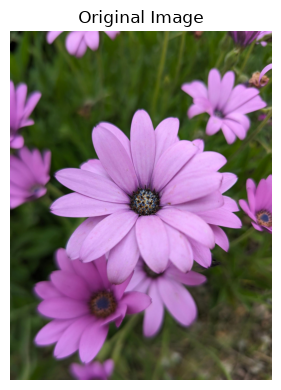

In [2]:
flower = read_bgr('flower.jpg')

# Desktop OpenCV window (skipped safely in headless notebook environments).
try:
    has_gui = (os.name == 'nt') or os.environ.get('IPP_ENABLE_OPENCV_GUI') == '1'
    if has_gui:
        cv2.imshow('Original Image', flower)
        cv2.waitKey(1)
        cv2.destroyWindow('Original Image')
        print('Opened OpenCV window: Original Image')
    else:
        print('No desktop display detected; showing the same image inline below.')
except cv2.error as exc:
    print('OpenCV GUI is unavailable; using the inline Matplotlib display instead:', str(exc).splitlines()[0])

show_bgr(flower, 'Original Image')


## Program 2 — Print the dimensions and datatype of `scene.jpg`

For a colour image, the OpenCV shape is `(height, width, channels)`. The datatype describes the stored pixel values.


In [3]:
scene = read_bgr('scene.jpg')
height, width, channels = scene.shape
print(f'Height: {height} pixels')
print(f'Width: {width} pixels')
print(f'Channels: {channels}')
print(f'Datatype: {scene.dtype}')


Height: 480 pixels
Width: 640 pixels
Channels: 3
Datatype: uint8


## Program 3 — Convert a colour image to grayscale and save `output_gray.jpg`


Saved: output_gray.jpg | shape: (2560, 1920) | dtype: uint8


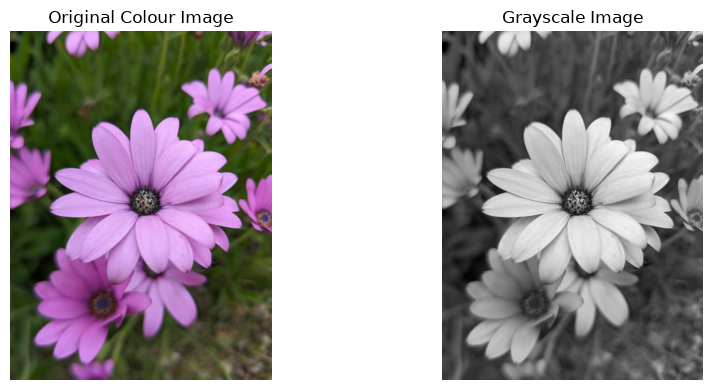

In [4]:
colour_image = read_bgr('flower.jpg')
gray_image = cv2.cvtColor(colour_image, cv2.COLOR_BGR2GRAY)
output_gray_path = BASE_DIR / 'output_gray.jpg'
if not cv2.imwrite(str(output_gray_path), gray_image):
    raise OSError(f'Could not save {output_gray_path}')
print('Saved:', output_gray_path.name, '| shape:', gray_image.shape, '| dtype:', gray_image.dtype)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(colour_image, cv2.COLOR_BGR2RGB)); plt.title('Original Colour Image'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(gray_image, cmap='gray'); plt.title('Grayscale Image'); plt.axis('off')
plt.tight_layout(); plt.show()


## Program 4 — Open `sunset.png` using Pillow and display it


Pillow image size (width, height): (4000, 6000)
Pillow image mode: RGBA


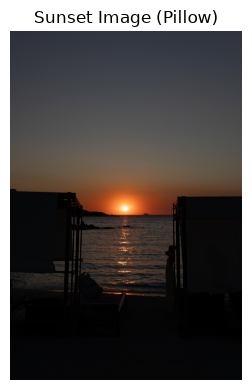

In [5]:
sunset_path = IMAGE_DIR / 'sunset.png'
with Image.open(sunset_path) as sunset:
    print('Pillow image size (width, height):', sunset.size)
    print('Pillow image mode:', sunset.mode)
    plt.figure(figsize=(7, 4))
    plt.imshow(sunset.convert('RGB'))
    plt.title('Sunset Image (Pillow)')
    plt.axis('off')
    plt.tight_layout()
    plt.show()


## Program 5 — Resize an image to 50% of its original width and height

OpenCV expects the target size in `(width, height)` order.


Original (width, height): (1920, 2560)
Resized (width, height): (960, 1280)


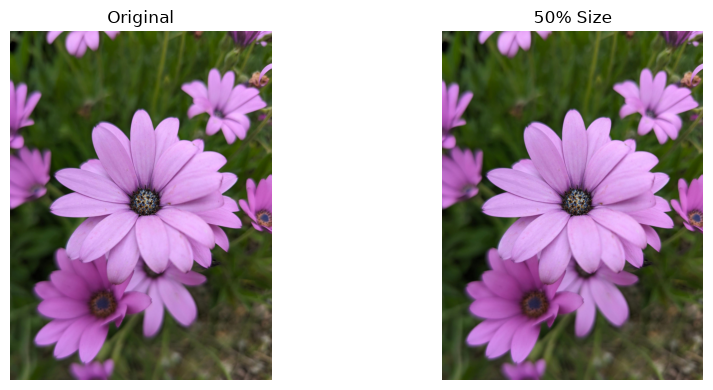

In [6]:
resize_source = read_bgr('flower.jpg')
h, w = resize_source.shape[:2]
new_size = (max(1, int(round(w * 0.5))), max(1, int(round(h * 0.5))))
resized_50 = cv2.resize(resize_source, new_size, interpolation=cv2.INTER_AREA)
print(f'Original (width, height): {(w, h)}')
print(f'Resized (width, height): {new_size}')
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(resize_source, cv2.COLOR_BGR2RGB)); plt.title('Original'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(resized_50, cv2.COLOR_BGR2RGB)); plt.title('50% Size'); plt.axis('off')
plt.tight_layout(); plt.show()


## Program 6 — Crop the central 200 × 200 pixel region and display it using Matplotlib

The image is checked before slicing so that the crop contains exactly 200 × 200 pixels.


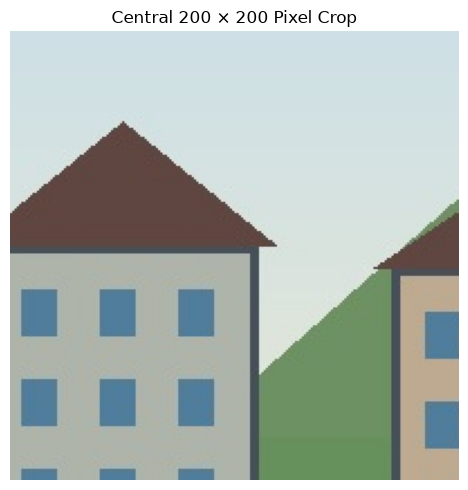

In [7]:
crop_source = read_bgr('scene.jpg')
h, w = crop_source.shape[:2]
if h < 200 or w < 200:
    raise ValueError(f'Image must be at least 200 x 200; received {w} x {h}')
x1, y1 = (w - 200) // 2, (h - 200) // 2
central_crop = crop_source[y1:y1+200, x1:x1+200]
assert central_crop.shape[:2] == (200, 200)
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(central_crop, cv2.COLOR_BGR2RGB))
plt.title('Central 200 × 200 Pixel Crop')
plt.axis('off'); plt.tight_layout(); plt.show()


## Program 7 — Rotate an image 90 degrees clockwise using OpenCV


Before rotation: (2560, 1920, 3)
After rotation: (1920, 2560, 3)


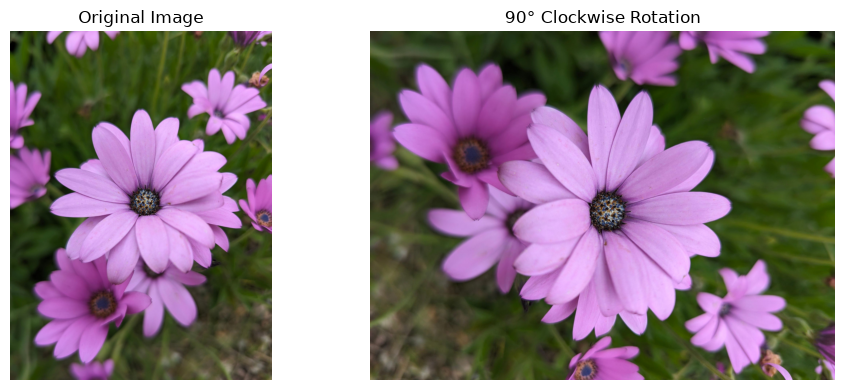

In [8]:
# Load the original image
rotation_source = read_bgr('flower.jpg')

# Rotate the image 90 degrees clockwise
rotated_90 = cv2.rotate(
    rotation_source,
    cv2.ROTATE_90_CLOCKWISE
)

# Print dimensions before and after rotation
print('Before rotation:', rotation_source.shape)
print('After rotation:', rotated_90.shape)

# Display original and rotated images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(rotation_source, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(rotated_90, cv2.COLOR_BGR2RGB))
plt.title('90° Clockwise Rotation')
plt.axis('off')

plt.tight_layout()
plt.show()

## Program 8 — Flip `car.jpg` horizontally (left-to-right) using OpenCV

A flip code of `1` performs a horizontal mirror.


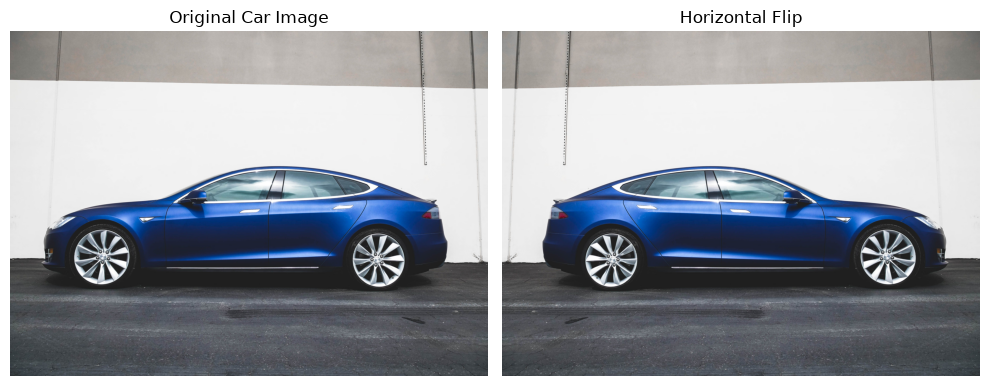

In [9]:
car = read_bgr('car.jpg')
car_flipped = cv2.flip(car, 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(car, cv2.COLOR_BGR2RGB)); plt.title('Original Car Image'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(car_flipped, cv2.COLOR_BGR2RGB)); plt.title('Horizontal Flip'); plt.axis('off')
plt.tight_layout(); plt.show()


## Program 9 — Convert RGB to HSV and display Hue, Saturation and Value channels

OpenCV loads `car.jpg` as BGR. It is first converted to RGB and then to HSV so the code matches the stated RGB-to-HSV operation.


C:\Users\PC\AppData\Local\Temp\ipykernel_18528\4098504298.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


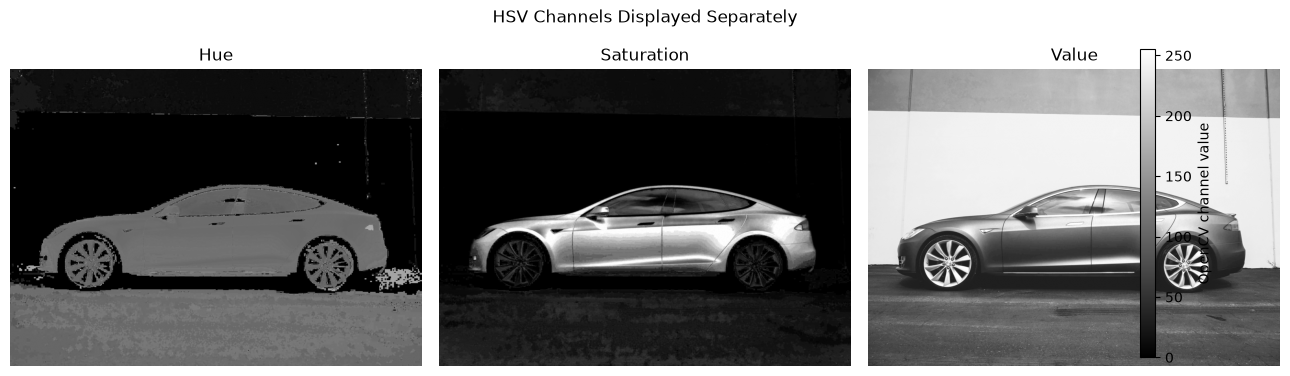

In [10]:
car_rgb = cv2.cvtColor(read_bgr('car.jpg'), cv2.COLOR_BGR2RGB)
car_hsv = cv2.cvtColor(car_rgb, cv2.COLOR_RGB2HSV)
hue, saturation, value = cv2.split(car_hsv)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, channel, title in zip(axes, [hue, saturation, value], ['Hue', 'Saturation', 'Value']):
    imshow = ax.imshow(channel, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title); ax.axis('off')
fig.colorbar(imshow, ax=axes, fraction=0.025, pad=0.02, label='OpenCV channel value')
fig.suptitle('HSV Channels Displayed Separately')
plt.tight_layout(); plt.show()


## Program 10 — Compute Mean Squared Error (MSE) between `img1.jpg` and `img2.jpg`

MSE is calculated only after both grayscale images are verified to have identical dimensions. No silent resizing is performed because resizing unrelated images can change the meaning of the comparison.

\[ MSE = \frac{1}{N} \sum_{i=1}^{N}(I_i - K_i)^2 \]


img1 shape: (256, 256)
img2 shape: (256, 256)
Mean Squared Error (MSE): 35.2086


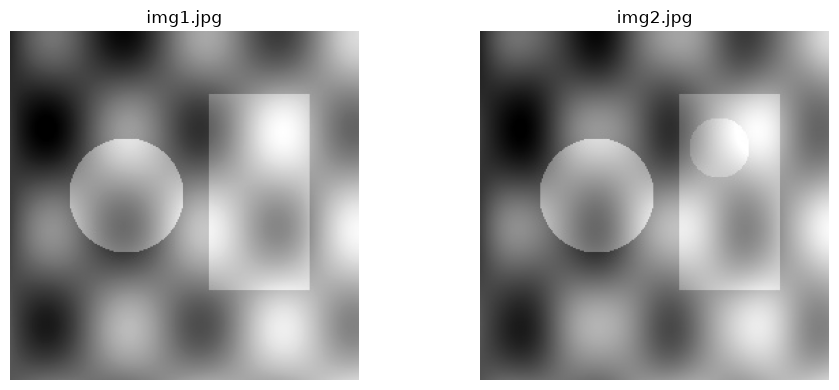

In [11]:
img1 = cv2.imread(str(IMAGE_DIR / 'img1.jpg'), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(str(IMAGE_DIR / 'img2.jpg'), cv2.IMREAD_GRAYSCALE)
if img1 is None or img2 is None:
    raise FileNotFoundError('Could not load img1.jpg or img2.jpg in grayscale mode')
if img1.shape != img2.shape:
    raise ValueError(f'MSE requires matching shapes; got {img1.shape} and {img2.shape}. Resize/alignment must be an explicit decision.')
mse_value = mean_squared_error(img1, img2)
if not np.isfinite(mse_value):
    raise ArithmeticError('MSE calculation returned a non-finite value')
print('img1 shape:', img1.shape)
print('img2 shape:', img2.shape)
print(f'Mean Squared Error (MSE): {mse_value:.4f}')
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img1, cmap='gray'); plt.title('img1.jpg'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img2, cmap='gray'); plt.title('img2.jpg'); plt.axis('off')
plt.tight_layout(); plt.show()


## Conclusion

The ten assigned programs have been implemented with bundled image inputs. The notebook demonstrates OpenCV reading, image metadata, grayscale conversion, Pillow display, resizing, cropping, rotation, flipping, HSV channel visualisation and MSE calculation. The MSE program explicitly checks shape compatibility before comparing the two grayscale arrays.
